# Deep Learning Assignment (IA-2)

### Team Members
- **Sai Anirudh** — 16014223071  
- **Vaibhav Bhatt** — 16014223089

## Architecture / Model Used

This project utilizes multiple deep learning architectures for image classification:

- **EfficientNet-B0** with CBAM attention
- **ResNet50** with CBAM attention
- **DenseNet121**

These models were selected due to their ability to extract rich hierarchical features. Attention mechanisms (CBAM) were incorporated to improve focus on important regions, and dropout was used to reduce overfitting.

In [1]:
import torch
print(torch.cuda.is_available())

True


In [2]:
print(torch.cuda.get_device_name(0))


NVIDIA GeForce RTX 5050 Laptop GPU


Setting the device to cude(GPU) if available

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
# Importing required libraries 
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split,Subset,WeightedRandomSampler
train_dataset: Subset
from collections import Counter
import numpy as np
import random



To ensure consistent and reproducible results, a fixed random seed **100** was used across dataset splitting, data loading, and model training processes.

In [5]:
seed = 100
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

Data augmentation techniques such as flipping, rotation, and color adjustments are applied to reduce overfitting. Images are then converted to tensors and normalized for as per the needs of pretrained models.

In [6]:

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),        
    
   
    
    transforms.RandomHorizontalFlip(),    
    transforms.RandomVerticalFlip(),     
    transforms.RandomRotation(10),      
    
    transforms.ColorJitter(
        brightness=0.15,                  
        contrast=0.15,                    
        saturation=0.1,                  
        hue=0.05                          
    ),
    
    transforms.ToTensor(),
    
    transforms.Normalize(                 
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

Validation size is resized and converted to tensors for further training

In [7]:
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)), 
    
    transforms.ToTensor(),
    
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [8]:
df = datasets.ImageFolder(root = "Faulty_solar_panel") #Data is loaded

Dataset is split into training and validation set in 80-20 ratio,

In [9]:
train_s = int(0.8*len(df))
val_s = len(df )- train_s
generator = torch.Generator().manual_seed(100)
train_indices, val_indices = random_split(
    df,
    [train_s, val_s],
    generator=generator
)



The dataset is loaded using `ImageFolder`. Separate datasets are created for training and validation with different transformations. 

Subset method is used to apply the augmentaion just for training data

In [10]:
train_df = datasets.ImageFolder(
    root="Faulty_solar_panel",
    transform=train_transforms
)

val_df = datasets.ImageFolder(
    root="Faulty_solar_panel",
    transform=val_transforms
)
# splitting the data after applying the transform
train_dataset = Subset(train_df, train_indices.indices) #Augemented data
val_dataset = Subset(val_df, val_indices.indices) # no augmentation


In [11]:
# Counting the number of images per class
labels = [train_dataset[i][1] for i in range(len(train_dataset))]
class_counts = Counter(labels)
for class_name, idx in train_df.class_to_idx.items():
    print(class_name, ":", class_counts[idx])

Bird-drop : 166
Clean : 152
Dusty : 151
Electrical-damage : 88
Physical-Damage : 56
Snow-Covered : 95


As we can see the number of physical-damage images are less leading to class imbalance which is solved by weighted sampler which balances the dataset by giving higher sampling to less class data points

In [12]:

print("Class counts:", class_counts)        
weights = [1.0 / class_counts[label] for label in labels]
sampler = WeightedRandomSampler(
    weights,
    num_samples=len(weights) * 2,   
    replacement=True
)

Class counts: Counter({0: 166, 1: 152, 2: 151, 5: 95, 3: 88, 4: 56})


In [13]:
#Applying the above fixes to the dataset
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    sampler=sampler,
    worker_init_fn=lambda id: np.random.seed(seed),
    generator=torch.Generator().manual_seed(seed)
)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [14]:
print(len(train_loader))
print(len(val_loader))

45
6


### CBAM(Convolutional Block Attention Module) 
This model is used for focusing more on the important features

In [15]:
# CBAM model

import torch.nn as nn
import torchvision.models as models

class ChannelAttention(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Linear(in_channels, in_channels // reduction),
            nn.ReLU(),
            nn.Linear(in_channels // reduction, in_channels)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.size()
        avg_out = self.fc(self.avg_pool(x).view(b, c))
        max_out = self.fc(self.max_pool(x).view(b, c))
        out = avg_out + max_out
        return self.sigmoid(out).view(b, c, 1, 1)


class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        x = torch.cat([avg_out, max_out], dim=1)
        x = self.conv(x)
        return self.sigmoid(x)


class CBAM(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.ca = ChannelAttention(in_channels)
        self.sa = SpatialAttention()

    def forward(self, x):
        x = x * self.ca(x)
        x = x * self.sa(x)
        return x

### EFFICIENT-B0 Model 
The above mentioned model is used as the pretrained backbone along with it we added the CBAM attention and dropout for better generalization

In [16]:
class EfficientNet_CBAM(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        base = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        self.features = base.features

        self.cbam = CBAM(1280)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(1280, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.cbam(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)

### ResNet-50 Model 
The above mentioned model is used as the pretrained backbone along with it we added the CBAM attention and dropout for better generalization

In [17]:
class ResNet_CBAM(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        base = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.features = nn.Sequential(*list(base.children())[:-2])
        self.cbam = CBAM(2048)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Dropout(0.5),          
            nn.Linear(2048, num_classes)
        )
        
    def forward(self, x):
        x = self.features(x)
        x = self.cbam(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)         

### DenseNet121 Model

A pretrained DenseNet121 model is used as the backbone for feature extraction. Dropout is applied to improve generalization and reduce overfitting.

Unlike EfficientNet and ResNet, CBAM attention is not used here. DenseNet inherently captures rich feature representations through dense connectivity, where each layer receives features from all previous layers. This reduces the need for additional attention mechanisms while keeping the model efficient and less complex.

In [18]:
class DenseNet_Model(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        base = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        self.features = base.features
        
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),                  
            nn.Linear(1024, num_classes)
        )
    def forward(self, x):
        x = self.features(x)
        x = torch.relu(x)
       
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        return self.classifier(x)           

In [19]:
#Initializing the model
efficient_model = EfficientNet_CBAM().to(device)
resnet_model = ResNet_CBAM().to(device)
densenet_model = DenseNet_Model().to(device)

The below block is for evaluation of the model on the validation set:
Uses this as its formula<br>
**Accuracy = (Correct Predictions / Total Samples) × 100**

In [20]:
def evaluate(model, loader, device):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


The models is trained using backpropagation with Adam optimizer, minimizing CrossEntropyLoss with label smoothing

In [21]:
for param in efficient_model.features.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = torch.optim.Adam(efficient_model.parameters(), lr=0.0001)

epochs = 20

eff_loss = []
eff_val = []   

for epoch in range(epochs):
    efficient_model.train()
    running_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = efficient_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

   
    eff_loss.append(running_loss / len(train_loader))

    
    acc = evaluate(efficient_model, val_loader, device)
    eff_val.append(acc)

    print(f"Epoch {epoch+1}, Loss: {running_loss / len(train_loader)}, Val Acc: {acc:.2f}%")

Epoch 1, Loss: 1.7034166733423868, Val Acc: 76.27%
Epoch 2, Loss: 1.2751532660590277, Val Acc: 79.66%
Epoch 3, Loss: 0.8741647534900241, Val Acc: 85.31%
Epoch 4, Loss: 0.6693876001569959, Val Acc: 88.14%
Epoch 5, Loss: 0.5950373788674672, Val Acc: 88.70%
Epoch 6, Loss: 0.5779751592212253, Val Acc: 88.70%
Epoch 7, Loss: 0.5271582153108385, Val Acc: 89.27%
Epoch 8, Loss: 0.5319315665298038, Val Acc: 89.83%
Epoch 9, Loss: 0.5070236490832435, Val Acc: 88.70%
Epoch 10, Loss: 0.5009759717517429, Val Acc: 90.40%
Epoch 11, Loss: 0.49469817280769346, Val Acc: 90.40%
Epoch 12, Loss: 0.4951943483617571, Val Acc: 89.83%
Epoch 13, Loss: 0.4832058548927307, Val Acc: 89.83%
Epoch 14, Loss: 0.4937799334526062, Val Acc: 89.83%
Epoch 15, Loss: 0.47955728835529754, Val Acc: 89.83%
Epoch 16, Loss: 0.46895291341675654, Val Acc: 89.83%
Epoch 17, Loss: 0.4837239649560716, Val Acc: 90.96%
Epoch 18, Loss: 0.473857973019282, Val Acc: 90.40%
Epoch 19, Loss: 0.47594669461250305, Val Acc: 90.40%
Epoch 20, Loss: 0.

In [22]:
print(f"EfficientNet_CBAM Accuracy: {evaluate(efficient_model,val_loader,device)}")

EfficientNet_CBAM Accuracy: 90.3954802259887


In [23]:
#Saving the Model
torch.save(efficient_model.state_dict(), "Models/efficient_100.pth")

In [24]:
for param in resnet_model.features.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.Adam(resnet_model.parameters(), lr=0.0001)

epochs = 20

res_losses = []
res_accs = []   

for epoch in range(epochs):

    resnet_model.train()
    running_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = resnet_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    res_losses.append(running_loss / len(train_loader))

    acc = evaluate(resnet_model, val_loader, device)
    res_accs.append(acc)

    print(f"Epoch {epoch+1}, Loss: {running_loss / len(train_loader)}, Val Acc: {acc:.2f}%")

Epoch 1, Loss: 1.7304111003875733, Val Acc: 64.41%
Epoch 2, Loss: 1.0978380017810399, Val Acc: 85.88%
Epoch 3, Loss: 0.6899568716684977, Val Acc: 88.70%
Epoch 4, Loss: 0.5871738460328844, Val Acc: 90.40%
Epoch 5, Loss: 0.5493959936830732, Val Acc: 91.53%
Epoch 6, Loss: 0.5250880453321669, Val Acc: 91.53%
Epoch 7, Loss: 0.48656269245677525, Val Acc: 91.53%
Epoch 8, Loss: 0.4919116073184543, Val Acc: 90.96%
Epoch 9, Loss: 0.4898927516407437, Val Acc: 93.22%
Epoch 10, Loss: 0.4801900863647461, Val Acc: 93.22%
Epoch 11, Loss: 0.4716518647140927, Val Acc: 92.66%
Epoch 12, Loss: 0.4731899552875095, Val Acc: 92.09%
Epoch 13, Loss: 0.470847436454561, Val Acc: 90.96%
Epoch 14, Loss: 0.4712063690026601, Val Acc: 91.53%
Epoch 15, Loss: 0.4725658251179589, Val Acc: 93.22%
Epoch 16, Loss: 0.46329132384724087, Val Acc: 92.09%
Epoch 17, Loss: 0.45179997550116646, Val Acc: 90.96%
Epoch 18, Loss: 0.45867190361022947, Val Acc: 90.40%
Epoch 19, Loss: 0.45535109175576105, Val Acc: 90.96%
Epoch 20, Loss: 0

In [25]:
print(f"ResNet_CBAM Accuracy: {evaluate(resnet_model,val_loader,device)}")

ResNet_CBAM Accuracy: 91.52542372881356


In [26]:
torch.save(resnet_model.state_dict(), "Models/resnet100.pth")

In [27]:
for param in densenet_model.features.parameters():
    param.requires_grad = True

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.Adam(densenet_model.parameters(), lr=0.0001)

epochs = 20

den_losses = []
den_accs = []   
for epoch in range(epochs):
    densenet_model.train()
    running_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = densenet_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    den_losses.append(running_loss / len(train_loader))

    acc = evaluate(densenet_model, val_loader, device)
    den_accs.append(acc)

    print(f"Epoch {epoch+1}, Loss: {running_loss / len(train_loader)}, Val Acc: {acc:.2f}%")

Epoch 1, Loss: 1.291418390803867, Val Acc: 83.05%
Epoch 2, Loss: 0.8008815209070842, Val Acc: 88.14%
Epoch 3, Loss: 0.6501339389218225, Val Acc: 90.96%
Epoch 4, Loss: 0.6177872207429674, Val Acc: 89.83%
Epoch 5, Loss: 0.5602520810233222, Val Acc: 90.40%
Epoch 6, Loss: 0.5260707636674246, Val Acc: 90.40%
Epoch 7, Loss: 0.5124285360177357, Val Acc: 89.27%
Epoch 8, Loss: 0.5167264574103885, Val Acc: 91.53%
Epoch 9, Loss: 0.5056075135866801, Val Acc: 89.83%
Epoch 10, Loss: 0.5030486484368643, Val Acc: 89.83%
Epoch 11, Loss: 0.49075996743308176, Val Acc: 89.83%
Epoch 12, Loss: 0.48702916304270427, Val Acc: 90.96%
Epoch 13, Loss: 0.48803176283836364, Val Acc: 89.83%
Epoch 14, Loss: 0.487865193022622, Val Acc: 89.83%
Epoch 15, Loss: 0.5017728825410207, Val Acc: 89.27%
Epoch 16, Loss: 0.49819069107373554, Val Acc: 90.96%
Epoch 17, Loss: 0.47972188194592796, Val Acc: 89.27%
Epoch 18, Loss: 0.49490579830275644, Val Acc: 89.27%
Epoch 19, Loss: 0.48594433069229126, Val Acc: 89.27%
Epoch 20, Loss: 

In [28]:
print(f"DenseNet Accuracy: {evaluate(densenet_model,val_loader,device)}")

DenseNet Accuracy: 89.26553672316385


In [29]:
torch.save(densenet_model.state_dict(), "Models/densenet100.pth")

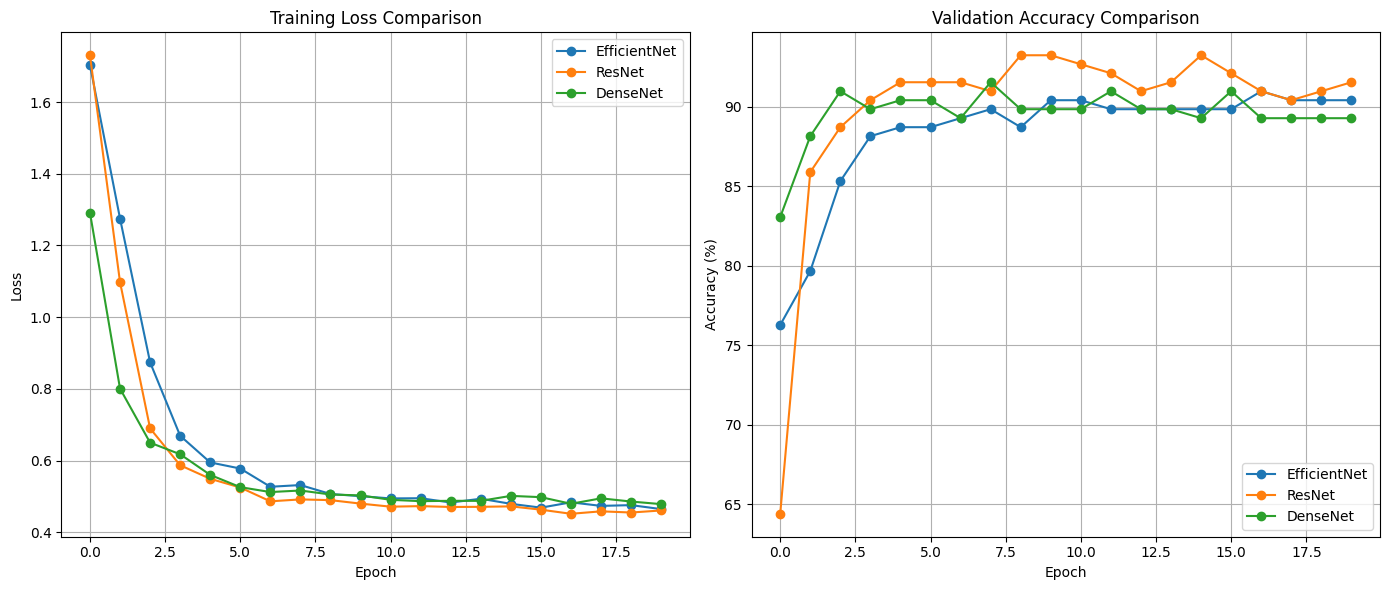

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))

# 🔹 LOSS COMPARISON
plt.subplot(1,2,1)
plt.plot(eff_loss, marker='o', label="EfficientNet")
plt.plot(res_losses, marker='o', label="ResNet")
plt.plot(den_losses, marker='o', label="DenseNet")

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

# 🔹 ACCURACY COMPARISON
plt.subplot(1,2,2)
plt.plot(eff_val, marker='o', label="EfficientNet")
plt.plot(res_accs, marker='o', label="ResNet")
plt.plot(den_accs, marker='o', label="DenseNet")

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

####  Models loaded from a checkpoint stored are loaded and are set in evaluation mode

In [30]:
efficient_model.load_state_dict(torch.load("Models/efficient_100.pth", map_location=device))
resnet_model.load_state_dict(torch.load("Models/resnet100.pth", map_location=device))
densenet_model.load_state_dict(torch.load("Models/densenet100.pth", map_location=device))

efficient_model.eval()
resnet_model.eval()
densenet_model.eval()

DenseNet_Model(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
       

### Ensemble + TTA(Test-time Augemntation)
Ensemble is used for improving prediction accuracy by combining multiple models output

TTA improves prediction stability by averaging outputs from multiple augmented versions of the same image during the test time

In [41]:
def ensemble_predict(images):
    images = images.to(device)

    with torch.no_grad():
        # original
        out1 = torch.softmax(efficient_model(images), dim=1)
        out2 = torch.softmax(resnet_model(images), dim=1)
        out3 = torch.softmax(densenet_model(images), dim=1)

        # flipped version
        flipped = torch.flip(images, dims=[3])
        

        out1_f = torch.softmax(efficient_model(flipped), dim=1)
        out2_f = torch.softmax(resnet_model(flipped), dim=1)
        out3_f = torch.softmax(densenet_model(flipped), dim=1)

        # average both
        out1 = (out1 + out1_f) / 2
        out2 = (out2 + out2_f) / 2
        out3 = (out3 + out3_f) / 2

        final_output = (
            0.25 * out1 +   # EfficientNet 
            0.5 * out2 +    # ResNet
            0.25 * out3    # DenseNet
        )

        _, predicted = torch.max(final_output, 1)

    return predicted

Checking the accuracy

In [42]:
correct = 0
total = 0
for images, labels in val_loader:
    images = images.to(device)
    labels = labels.to(device)

    preds = ensemble_predict(images)

    total += labels.size(0)
    correct += (preds == labels).sum().item()

accuracy = 100 * correct / total
print(f"Ensemble Accuracy: {accuracy:.2f}%")

Ensemble Accuracy: 93.22%


### Classification Report

In [43]:
from sklearn.metrics import classification_report

all_preds, all_labels = [], []
for images, labels in val_loader:
    preds = ensemble_predict(images)
    all_preds.extend(preds.cpu().numpy())
    all_labels.extend(labels.numpy())

print(classification_report(all_labels, all_preds, target_names=df.classes))

                   precision    recall  f1-score   support

        Bird-drop       0.91      0.95      0.93        41
            Clean       0.93      0.90      0.91        41
            Dusty       0.90      0.90      0.90        39
Electrical-damage       0.94      1.00      0.97        15
  Physical-Damage       1.00      0.85      0.92        13
     Snow-Covered       1.00      1.00      1.00        28

         accuracy                           0.93       177
        macro avg       0.94      0.93      0.94       177
     weighted avg       0.93      0.93      0.93       177



## Custom Images checking

In [48]:
import os
from PIL import Image
import matplotlib.pyplot as plt

def Custom(folder):
    correct = 0
    total = 0

    for class_name in os.listdir(folder):
        class_path = os.path.join(folder, class_name)

        if not os.path.isdir(class_path):
            continue

        for img_name in os.listdir(class_path):
            img_path = os.path.join(class_path, img_name)

            try:
                img = Image.open(img_path).convert("RGB")
            except:
                continue

            input_img = val_transforms(img).unsqueeze(0).to(device)
            pred = ensemble_predict(input_img).item()

            predicted_label = df.classes[pred]

           
            total += 1
            if predicted_label.lower() == class_name.lower():
                correct += 1

            color = "green" if predicted_label.lower() == class_name.lower() else "red"

            plt.imshow(img)
            plt.title(f"Pred: {predicted_label} | Actual: {class_name}", color=color)
            plt.axis("off")
            plt.show()

    
    accuracy = 100 * correct / total if total > 0 else 0
    print(f"Accuracy of the predictions: {accuracy:.2f}% ({correct}/{total})")

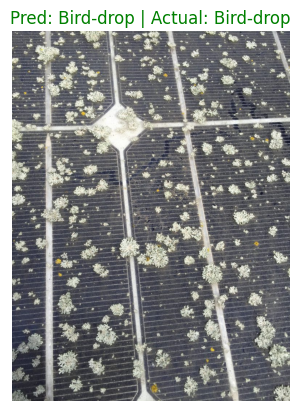

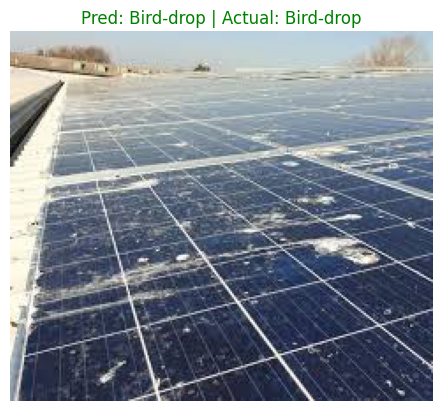

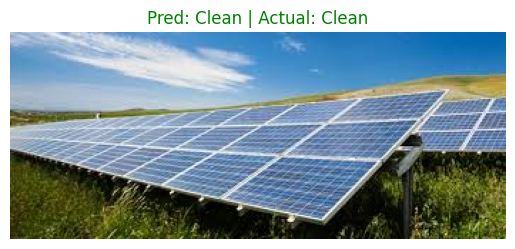

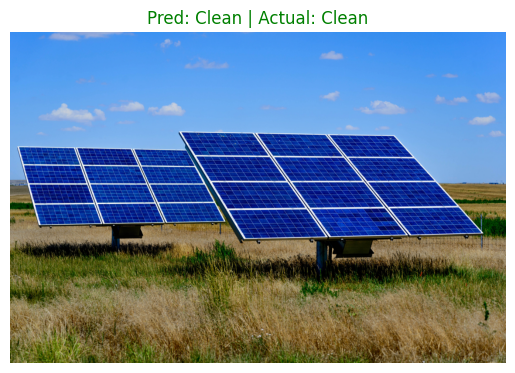

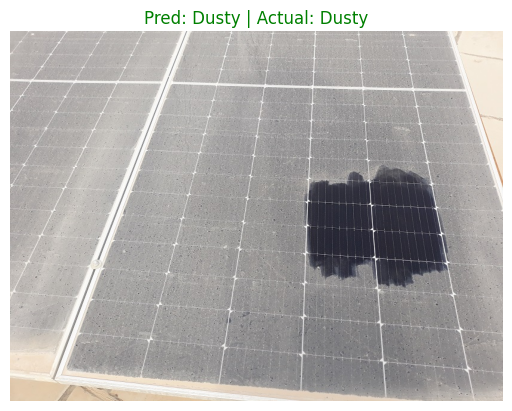

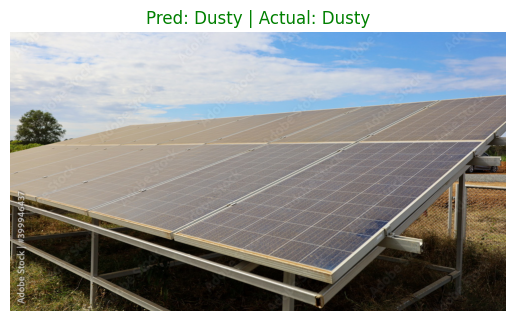

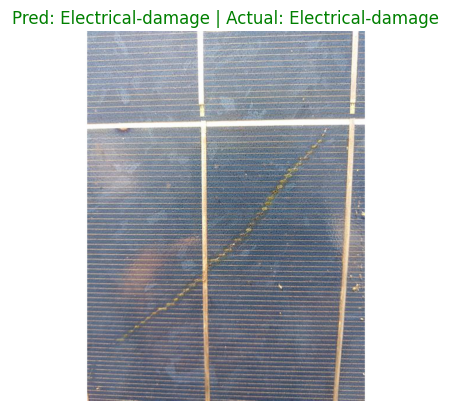

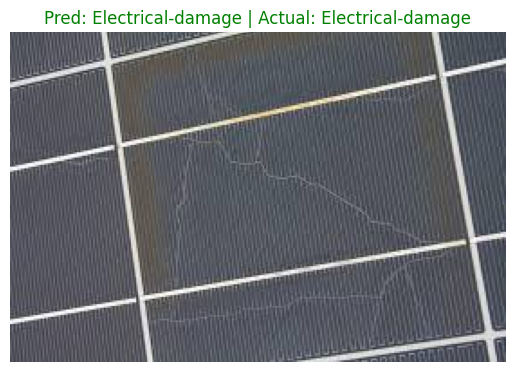

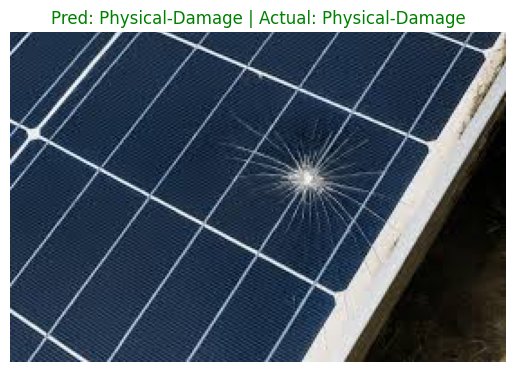

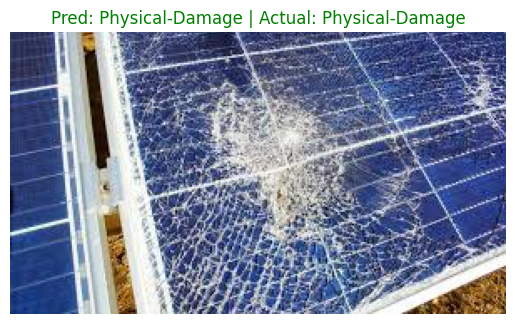

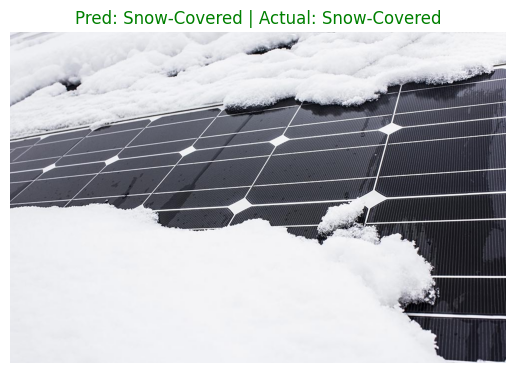

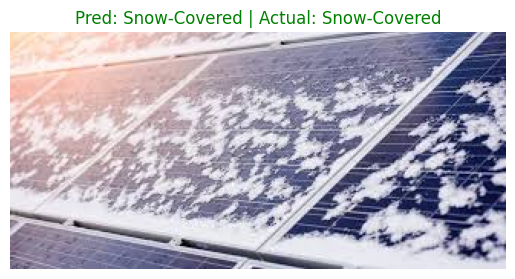

Accuracy of the predictions: 100.00% (12/12)


In [49]:
Custom("Solar_Panel_custom")